# Lab 25: Evaluating LLM Hallucinations in Security Answers

*AI Cybersecurity Masterclass · Lab 25 · AI60secLab*

**Companion video:** [▶ How to Test LLM Hallucinations in Cybersecurity in 60 Seconds](https://www.youtube.com/watch?v=iCBlRHD7bxw&list=PLG4l6Ssi9A00)

**Research question:** How do you know a confident AI security answer is not hallucinating?

We evaluate answers about ATT&CK techniques against the official ATT&CK STIX data. Two simulated systems write equally fluent, confident text: one answers from memory (closed-book), one answers from retrieved ATT&CK records (retrieval-grounded).

**Learning objectives**
- break a free-text answer into checkable claims;
- verify each claim against source evidence;
- classify failures before trying to fix them;
- score with a multi-dimensional rubric instead of one number;
- compare two systems fairly on the same questions and rubric.

> **About the simulated systems.** Both generators produce confident text with controlled error rates, so the evaluator has something realistic to catch. The evaluator itself (claim extraction, verification against ATT&CK, the failure taxonomy, the rubric) is real and works on any model's output: replace `run_generator` with your model's answers and keep everything else.

In [1]:
# Setup: works in Google Colab and locally. No uploads needed.
# In Colab this clones the course repo, which already includes the UNSW-NB15 data.
from pathlib import Path
import sys, os

REPO_URL = "https://github.com/Jacquelinepersha/ai-cybersecurity-public-labs.git"
REPO_NAME = "ai-cybersecurity-public-labs"

try:
    import google.colab  # noqa: F401
    if not Path(REPO_NAME).exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir(REPO_NAME)
except ImportError:
    pass

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

Project root: /home/claude/run/new
Data folder : /home/claude/run/new/data/raw


In [2]:
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)
import matplotlib.pyplot as plt

from src.mitre_data import ATTACK_ENTERPRISE_URL, load_remote_or_local
from src.llm_eval import (
    build_truth,
    make_questions,
    run_generator,
    extract_claims,
    evaluate_answers,
    rubric,
)

attack_bundle = load_remote_or_local(ATTACK_ENTERPRISE_URL, local_path=DATA_DIR / "enterprise-attack.json")
truth = build_truth(attack_bundle)
print("Active techniques:", len(truth["techniques"]), "| retired IDs:", len(truth["retired"]), "| groups:", len(truth["group_names"]))

questions = make_questions(truth, n=120, seed=0)
closed = run_generator(truth, questions, "closed-book", seed=1)
grounded = run_generator(truth, questions, "retrieval-grounded", seed=2)
answers = pd.concat([closed, grounded], ignore_index=True)

Active techniques: 706 | retired IDs: 161 | groups: 178


## Step 1: Same tone, different truth

Read both answers to the same question. Nothing in the wording tells you which one is wrong.

In [3]:
for i in range(3):
    print("Q:", questions.loc[i, "question"])
    print("  closed-book:       ", closed.loc[i, "answer"])
    print("  retrieval-grounded:", grounded.loc[i, "answer"])
    print()

Q: Which ATT&CK technique is 'Active Scanning'? Give its ID, tactic, and one group known to use it.
  closed-book:        Active Scanning is ATT&CK technique T1595, under the reconnaissance tactic. It is used by Salt Typhoon.
  retrieval-grounded: Active Scanning is ATT&CK technique T1595, under the reconnaissance tactic. It is used by Salt Typhoon. Source: MITRE ATT&CK T1595.

Q: Which ATT&CK technique is 'Data Manipulation'? Give its ID, tactic, and one group known to use it.
  closed-book:        Data Manipulation is ATT&CK technique T1565, under the resource-development tactic. It is used by FIN13.
  retrieval-grounded: Data Manipulation is ATT&CK technique T1565, under the impact tactic. It is used by FIN13. Source: MITRE ATT&CK T1565.

Q: Which ATT&CK technique is 'Python'? Give its ID, tactic, and one group known to use it.
  closed-book:        Python is ATT&CK technique T1059.006, under the privilege-escalation tactic. It is used by UNC3886.
  retrieval-grounded: Python is ATT

## Step 2: Break each answer into checkable claims

In [4]:
display(pd.DataFrame(extract_claims(closed.loc[0, "answer"], truth)))

,type,value
0,technique_id,T1595
1,tactic,reconnaissance
2,group,Salt Typhoon
3,citation,NaN


## Step 3: Verify every claim against ATT&CK and classify the failures

In [5]:
claims = evaluate_answers(answers, truth)
failures = (
    claims[~claims["supported"]]
    .groupby(["system", "failure"]).size()
    .unstack(0).fillna(0).astype(int)
)
display(failures)

system,closed-book,retrieval-grounded
failure,,
citation does not support claim,15,0
fabricated entity,9,0
outdated (retired ID),2,0
unsupported (no citation),60,0
"wrong attribute (real ID, wrong technique)",12,2
wrong attribute (tactic),17,1
wrong relationship (group),42,3


Not all hallucinations look alike:
- a **fabricated entity** (an ID that does not exist) can be caught by lookup;
- a **wrong attribute** (a real ID for the wrong technique) passes a lookup and needs a cross-check;
- a **wrong relationship** (a real group that does not use this technique) is the most dangerous in CTI: it creates false attribution;
- an **outdated** claim uses a revoked or deprecated ID;
- an **unsupported** claim has no citation.

Each needs a different fix.

## Step 4: One score versus a rubric

In [6]:
single_score = claims.groupby("system")["supported"].mean().rename("share of all claims supported")
display(single_score.round(3).to_frame())

scores = rubric(claims)
display(scores.round(3))

,share of all claims supported
system,
closed-book,0.673
retrieval-grounded,0.988


system,closed-book,retrieval-grounded
claim_precision,0.772,0.982
id_accuracy,0.808,0.983
tactic_accuracy,0.858,0.992
group_accuracy,0.650,0.969
citation_validity,0.375,1.000
answers_with_critical_error,0.408,0.025
correct_abstentions,0.000,24.000


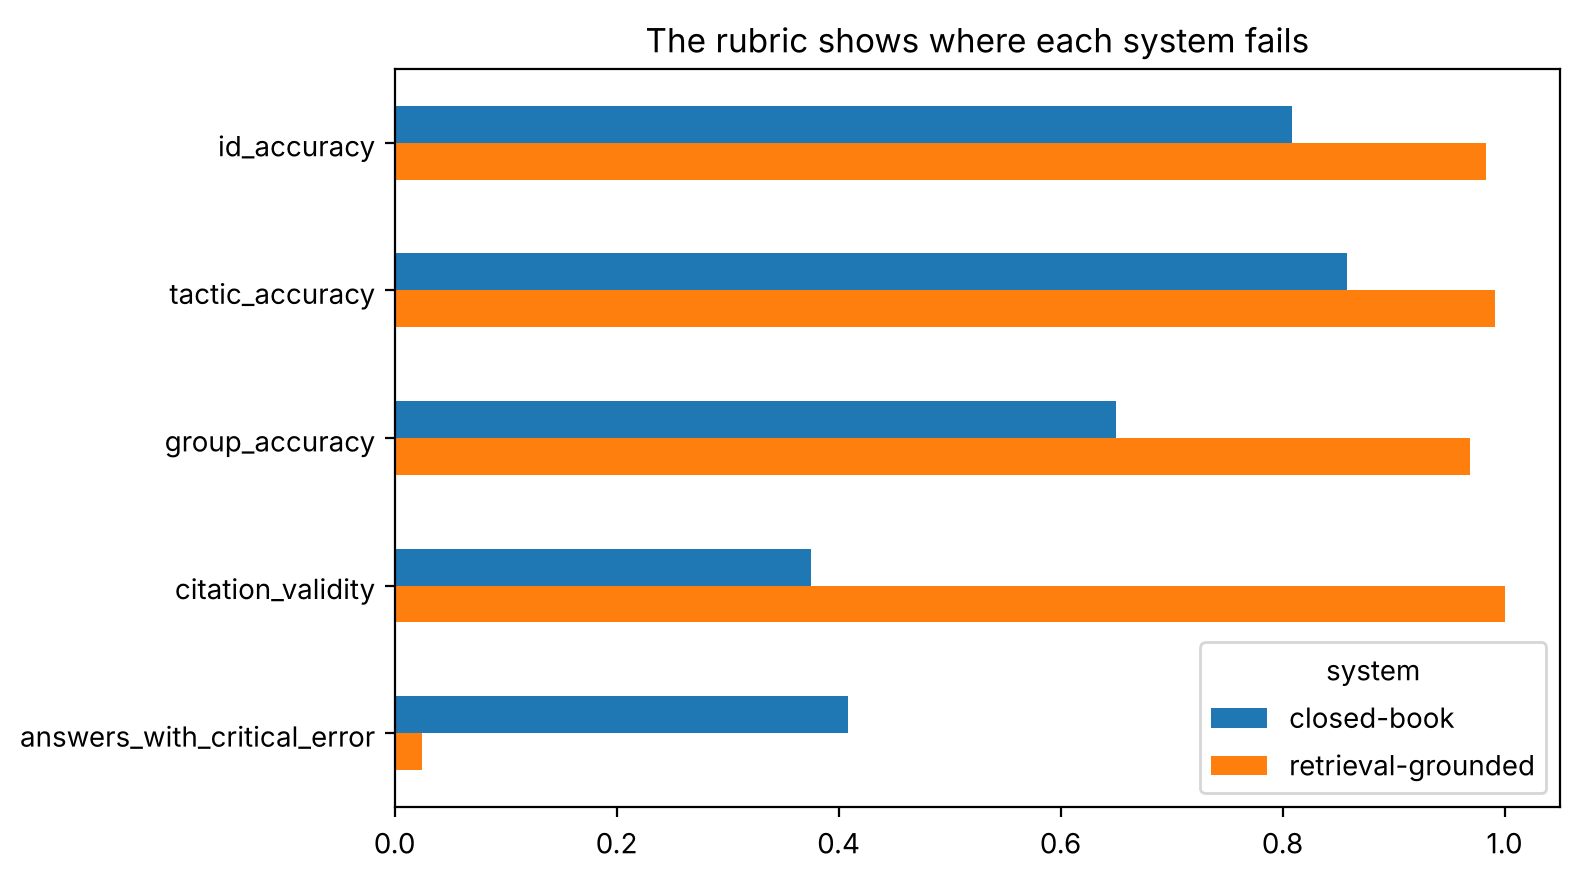

In [7]:
plot_rows = ["id_accuracy", "tactic_accuracy", "group_accuracy", "citation_validity", "answers_with_critical_error"]
fig, ax = plt.subplots(figsize=(8, 4.5))
scores.loc[plot_rows].plot(kind="barh", ax=ax)
ax.set_xlim(0, 1.05)
ax.set_title("The rubric shows where each system fails")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Step 5: Prevention plus evaluation

Retrieval reduces errors before output, and abstains ("insufficient data") when the evidence is missing. Evaluation measures what still gets through. Neither replaces the other.

In [8]:
abstentions = grounded[grounded["answer"].str.contains("Insufficient data")]
print("Grounded answers that abstained on the group question:", len(abstentions))
print("Example:", abstentions["answer"].iloc[0] if len(abstentions) else "none")

Grounded answers that abstained on the group question: 24
Example: Service Exhaustion Flood is ATT&CK technique T1499.002, under the impact tactic. Insufficient data: no group is linked to this technique in the retrieved ATT&CK data. Source: MITRE ATT&CK T1499.002.


## Interpretation

1. Which failure type is most common for the closed-book system, and what would fix it?
2. Why is "share of all claims supported" a misleading single number here?
3. The grounded system still makes some errors. Where would they come from in a real RAG system?
4. Why does a fair comparison need the same questions, the same claim extractor, and the same rubric for both systems?

**Takeaway:** evaluate the claims, not the tone. A repeatable rubric makes prompt and model comparisons fair.